# POGOH Bike Share Access by Neighborhood
**Yusuf Taniyici**

## Submetric: Bike Access Score
A neighborhood is better if it's easy to grab a bike. I score each neighborhood on how many POGOH docks it has for its size and how far you'd have to walk to the nearest station.

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

excel_path = "../datasets/pogoh-station-locations-may-2026.xlsx"
csv_path = "../datasets/pogoh-station-locations.csv"
hoods_path = "../datasets/neighborhoods.geojson"

if not os.path.exists(csv_path):
    pd.read_excel(excel_path, sheet_name=0, dtype=str).to_csv(csv_path, index=False, encoding="utf-8")

stations = pd.read_csv(csv_path)
stations.head()

,Id,Name,Total Docks,Latitude,Longitude
0,1,Pierce St & Summerlea St,19,40.456598,-79.932147
1,2,Eliza Furnace Trail & Swineburne St,15,40.425830,-79.953476
2,3,Centre Ave & Addison St,15,40.444500,-79.978292
3,4,Burns White Center at 3 Crossings,15,40.456379,-79.980205
4,5,Allegheny Station,19,40.448301,-80.018007


## Exploring the station data
First I want to know how many stations there are, whether anything is missing, and how big stations usually are.

In [2]:
print(stations.shape)
stations.info()

(60, 5)
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Id           60 non-null     int64  
 1   Name         60 non-null     str    
 2   Total Docks  60 non-null     int64  
 3   Latitude     60 non-null     float64
 4   Longitude    60 non-null     float64
dtypes: float64(2), int64(2), str(1)
memory usage: 2.5 KB


In [3]:
print("Missing values:\n", stations.isna().sum())
print("Duplicate station IDs:", stations["Id"].duplicated().sum())
stations["Total Docks"].describe()

Missing values:
 Id             0
Name           0
Total Docks    0
Latitude       0
Longitude      0
dtype: int64
Duplicate station IDs: 0


count    60.000000
mean     17.850000
std       3.129006
min      11.000000
25%      15.000000
50%      19.000000
75%      19.000000
max      27.000000
Name: Total Docks, dtype: float64

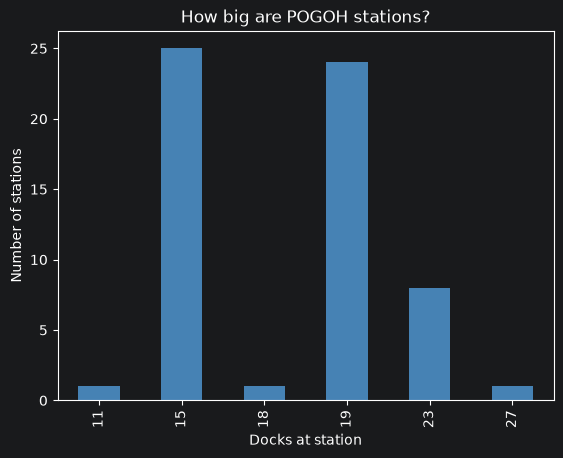

In [4]:
ax = stations["Total Docks"].value_counts().sort_index().plot(kind="bar", color="steelblue")
ax.set_xlabel("Docks at station")
ax.set_ylabel("Number of stations")
ax.set_title("How big are POGOH stations?")
plt.show()

In [5]:
stations.loc[stations["Total Docks"].idxmax()]

Id                                        29
Name           Filmore St & S Bellefield Ave
Total Docks                               27
Latitude                           40.445145
Longitude                         -79.951083
Name: 28, dtype: object

There are 60 stations. Most stations have 15 or 19 docks. The biggest is Filmore St & S Bellefield Ave in Oakland with 27.

Then, since there is no neighborhood info in the pogoh dataset, I do a spatial join against the WPDRC neighborhood boundaries to place the pogoh station points inside the neighborhoods from the neighborhoods.geojson file.

In [6]:
stations_gdf = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations["Longitude"], stations["Latitude"]),
    crs="EPSG:4326",
)

hoods = gpd.read_file(hoods_path).to_crs("EPSG:4326")
hoods.columns

Index(['OBJECTID', 'fid_blockg', 'statefp10', 'countyfp10', 'tractce10',
       'blkgrpce10', 'geoid10', 'namelsad10', 'mtfcc10', 'funcstat10',
       'aland10', 'awater10', 'intptlat10', 'intptlon10', 'shape_leng',
       'fid_neighb', 'perimeter', 'neighbor_', 'neighbor_i', 'hood', 'hood_no',
       'acres', 'sqmiles', 'dpwdiv', 'unique_id', 'sectors', 'shape_le_1',
       'shape_ar_1', 'page_number', 'plannerassign', 'created_user',
       'created_date', 'last_edited_user', 'last_edited_date', 'temp',
       'pghdb_sde_Neighborhood_2010_are', 'GlobalID', 'Shape__Area',
       'Shape__Length', 'geometry'],
      dtype='str')

In [7]:
HOOD_COL = "hood"
hoods = hoods[[HOOD_COL, "geometry"]].rename(columns={HOOD_COL: "neighborhood"})

joined = gpd.sjoin(stations_gdf, hoods, how="left", predicate="within")

joined[joined["neighborhood"].isna()][["Id", "Name"]]

,Id,Name
59,60,Wilkinsburg Park & Ride


Wilkinsburg Park & Ride are outside of the city, because Wilkinsburg is its own borough. I left it out of the per-neighborhood counts, but It still counts for the proximity measure since it still serves people in Homewood and East Hills.

In [8]:
in_city = joined.dropna(subset=["neighborhood"])

per_hood = (
    in_city.groupby("neighborhood")
    .agg(stations=("Id", "count"), docks=("Total Docks", "sum"))
    .sort_values("docks", ascending=False)
)
print(f"{len(per_hood)} of {hoods['neighborhood'].nunique()} neighborhoods have at least one station")
per_hood.head(10)

26 of 90 neighborhoods have at least one station


,stations,docks
neighborhood,,
Central Oakland,6,126
North Oakland,5,106
Central Business District,6,98
Shadyside,5,87
South Side Flats,4,76
Bloomfield,4,64
Allegheny Center,3,53
Strip District,3,53
Hazelwood,3,49
